In [ ]:
from clickhouse_driver import Client
import pandas as pd
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt 


client = Client(host='', port=0, user='',
                password='', database='')

result = client.execute('SELECT * FROM user_dm_events LIMIT 10')

def get_data(query):
    """
    Вытягивает данные из clickhouse в виде Dataframe
    
    query - запрос
    """
    result, columns = client.execute(query, with_column_types=True)
    return pd.DataFrame(result, columns=[tuple[0] for tuple in columns])




### Задача 1.
Представим, что сегодня 31 января 2023 года, и мы хотим помочь определить рыночную цену продавцам, которые собираются сегодня разместить свои объявления. Рынок автомобилей меняется довольно быстро, поэтому в этом кейсе будем обучать нашу модель только на объявлениях, которые были размещены вчера. Будем считать, что такие объявления лучше всего отражают текущую ситуацию на рынке.

Напишите запрос, чтобы выгрузить данные об объявлениях, созданных 30 января 2023 года (created_at). Помимо объявлений (таблица live_adverts) нам понадобится признак пользователей user_type_cars_name из таблицы user_passports.

##### Сколько строк у вас получилось в датасете?

In [47]:
start_data = get_data(f"""
    SELECT 
        la.*
        , up.user_type_cars_name
    FROM hardda.live_adverts as la 
    LEFT JOIN hardda.user_passports as up
        USING(passport_id) 
    WHERE 1=1
        AND CAST(created_at as DATE) = '2023-01-30'
""")

start_data['execution_date'] = pd.to_datetime(start_data['execution_date'])
start_data.head()

,execution_date,advert_id,created_at,price,region,user_id,platform,auto_brand,auto_model,passport_id,year,userType,user_type_cars_name
0,2023-01-30,271540910,2023-01-30 00:00:02,414000,Самара,134142241,ios,ЗАЗ,Chance,131631637,2014,0,cars_simple
1,2023-01-30,271540911,2023-01-30 00:00:17,620000,Сочи,151328585,ios,Chevrolet,Cruze,144703780,2010,0,cars_simple
2,2023-01-30,271540913,2023-01-30 00:01:21,4970000,Москва,123929189,android,Toyota,Land Cruiser,123950184,2013,6,cars_seller
3,2023-01-30,271540914,2023-01-30 00:04:42,800000,Москва,137723514,android,Subaru,Impreza,134075141,2006,0,cars_simple
4,2023-01-30,271540915,2023-01-30 00:04:57,280000,Пермь,142310446,android,Mitsubishi,RVR,137387157,1995,0,cars_simple


И сразу ещё одна вещь. В некоторых случаях Кликхауз возвращает '' (пустую строку) вместо NULL. Соответственно, в pandas-датафрейме будет '' вместо ожидаемого np.nan. Сейчас у нас именно так получилось в столбце user_type_cars_name (проверьте это).

Это довольно неудачная ситуация. Ни pandas, ни sklearn не распознает это как пропуск. При этом если сохранить датафрейм в csv и загрузить из файла, — вместо пустой строки появится np.nan, т.е. уже пропуск.

Наиболее правильным решением было бы сейчас заменить в этом столбце пустые строки на np.nan, а потом учесть это в пайплайне предобработки. Но давайте для простоты сразу заменим это значение на 'unknown' и будем считать это отдельной категорией.

Сколько строк у вас получилось в датасете?

In [48]:
print(start_data.user_type_cars_name.value_counts())
start_data['user_type_cars_name'] = start_data.user_type_cars_name.replace('', 'unknown')
print(start_data.shape[0])


user_type_cars_name
cars_simple    29196
cars_seller     3174
                3005
cars_dealer      668
Name: count, dtype: int64
36043


Можно заметить, что количество уникальных advert_id меньше, чем количество строк в датафрейме.

Например, для advert_id, равного 271540911, в данных есть две строки, которые отличаются только значением execution_date.

Наличие дубликатов (или "почти дубликатов") в данных это большая проблема для задач машинного обучения. Представим, что одна из таких строк попала в обучающую выборку, а другая в валидационную или тестовую. Тогда модель может просто "запомнить" пример из обучающей выборки вместо того, чтобы учиться искать закономерности (а учитывая, что сегодня у нас в качестве модели KNN, — тем более). Оценка качества модели получится завышенной. И будет плохо отражать то, как модель на самом деле будет справляться с предсказанием на новых данных.


Пойдём другим путём. Для каждого advert_id оставим только самые актуальные данные. Т.е. строку с максимальной execution_date.


Проверьте, что после этого количество строк в датафрейме совпадает с количеством уникальных advert_id (или что по каждому advert_id в данных только одна строка).

Сколько строк в полученном датафрейме и в скольких из них execution_date равна 2023-01-31? Введите два числа через запятую и пробел. Например, 20001, 15002.

In [49]:
dropped_data = start_data.sort_values(by='execution_date', ascending=False)\
    .drop_duplicates(subset='advert_id', keep='first')\
    .reset_index(drop=1)
dropped_data = dropped_data.sort_values(by='advert_id').reset_index(drop=1)
print(f'Количество строк в датафрейме и количество уникальных advert_id : {dropped_data.shape[0]}, {dropped_data.advert_id.nunique()}')

print(f'Ответ: {dropped_data.shape[0], dropped_data[dropped_data['execution_date'] == '2023-01-31'].shape[0]}')

Количество строк в датафрейме и количество уникальных advert_id : 20386, 20386
Ответ: (20386, 18318)


### Задача 3
В первую очередь обратим внимание на типы полей, а конкретно на поле “год выпуска машины”. Будет ли нам удобно анализировать его в таком виде? Исправьте тип поля на более подходящий.

В качестве ответа напишите новый тип поля. Тип пишите строчными (маленькими) буквами.


Обратим внимание, какое минимальное значение года выпуска автомобиля в нашем датасете. Адекватно ли на ваш взгляд это значение?

Мы могли бы заменить это значение на np.nan и работать с ним как с пропуском. Но в данном случае поступим проще: удалим все строки с таким значением года.

Какое минимальное значение было у года?

In [50]:
# dropped_data.dtypes
dropped_data.year = dropped_data.year.astype('int64')
print(dropped_data.dtypes.loc['year'])

drop_year = dropped_data.year.min()
print(drop_year)
data = dropped_data[dropped_data['year'] != drop_year]
data.year = data.year.astype('Int16')
data.head()



int64
0


,execution_date,advert_id,created_at,price,region,user_id,platform,auto_brand,auto_model,passport_id,year,userType,user_type_cars_name
0,2023-01-30,271540910,2023-01-30 00:00:02,414000,Самара,134142241,ios,ЗАЗ,Chance,131631637,2014,0,cars_simple
1,2023-01-31,271540911,2023-01-30 00:00:17,620000,Сочи,151328585,ios,Chevrolet,Cruze,144703780,2010,0,cars_simple
2,2023-01-31,271540913,2023-01-30 00:01:21,4970000,Москва,123929189,android,Toyota,Land Cruiser,123950184,2013,6,cars_seller
3,2023-01-31,271540914,2023-01-30 00:04:42,800000,Москва,137723514,android,Subaru,Impreza,134075141,2006,0,cars_simple
4,2023-01-31,271540915,2023-01-30 00:04:57,280000,Пермь,142310446,android,Mitsubishi,RVR,137387157,1995,0,cars_simple


Если вы построите распределение цены автомобилей, то увидите, что распределение далеко не нормальное. Это плохо, потому что наша модель будет стараться подстроиться под аномальные значения, и в итоге потеряет свою обобщающую способность.

Попробуем сделать распределение более симметричными с помощью удаления выбросов. Давайте будем считать, что цена на автомобиль меньше 1000 — аномально низкое значение. Удалите такие строки.

Постройте гистограмму нового распределения цены.

И прежде чем переходить к созданию пайплайна и обучению модели, давайте убедимся, что наши датасеты совпадают.

Сколько строк осталось в датасете после текущего шага?

(0.0, 8031999.999999971)

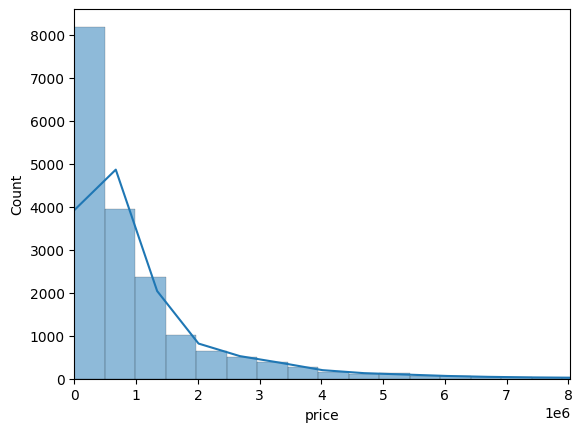

In [51]:
sns.histplot(data=data['price'], kde=True)
plt.xlim(0, data['price'].quantile(0.99))

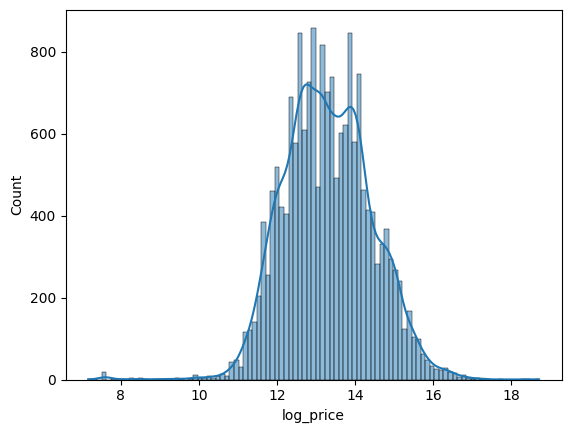

18021


In [52]:
data_log = data[data['price'] >= 1000].copy().reset_index(drop=1)
data_log['log_price'] = np.log(data_log['price'])
sns.histplot(data=data_log['log_price'], kde=True)
plt.show()

print(data_log.shape[0])

### Задача 4. Пайплайн
Подготовим всё для обучения модели.

X и y
Выделите из датафрейма X и y. Не забудьте, что в качестве таргета мы решили использовать логарифм цены, а не саму цену. И проследите, чтобы price не попала в X.

Разбейте данные на train/test в пропорции 80/20

Подготовим ColumnTransformer для категориальных столбцов:

Для столбцов, содержащих не более 5 уникальных значений, используйте OneHotEncoder с параметрами handle_unknown='ignore' и sparse_output=False. Устанавливать drop='first' не нужно (этот параметр полезен для линейных моделей и не очень нужен тут).
Для столбцов с более 5 уникальных категорий используйте TargetEncoder с параметрами target_type='continuous' и random_state=42.
Сделайте так, чтобы при применении трансформера остальные (не категориальные) столбцы не терялись, а оставались как есть.

Можете проверить, что получается, вызвав fit_transform на X_train, y_train.

Пайплайн предобработки
Теперь соберём пайплайн предобработки, состоящий из 2 шагов:

Созданного до этого трансформера для категориальных столбцов.
StandardScaler.
Тут тоже можно посмотреть глазами на промежуточные результаты, которые получаются после этого шага.

Итоговый пайплайн
И, наконец, соберём итоговый пайплайн, состоящий из пайплайна предобработки и, собственно, модели (KNeighborsRegressor, пока с параметрами по умолчанию). На следующем шаге мы обучим полученный пайплайн и проверим качество на кросс-валидации.

 

Для измерения качества модели будем использовать следующие метрики:

R2 — метрика со значением от 0 до 1. Показывает долю дисперсии целевой переменной, которую объясняет наша модель. Чем она выше, тем лучше. Может быть отрицательной, если наша модель работает хуже наивного прогноза.
MAE (mean absolute error).


Таким образом, чем ниже значение MAE, тем лучше.

Измерьте значение метрики R2 на кросс-валидации с помощью cross_val_score.

Модель — собранный пайплайн, данные — X_train и y_train, 5 фолдов (для простоты в этом уроке не будем явно создавать KFold, используйте cv=5 или не задавайте этот параметр совсем, т.к. 5 фолдов используется по умолчанию).

В поле ниже введите результат, усреднив по фолдам и округлив до 2 знаков. Например, 0.56.


Измерьте значение метрики MAE на кросс-валидации. Всё, как на предыдущем шаге, только другая метрика.

Вспомните или найдите, как передать в функцию эту метрику и какая там будет особенность.

Ответ округлите до сотых.

In [53]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, TargetEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import cross_val_score

columns_to_drop = [
    'price', 'log_price', 'execution_date', 'created_at', 
    'advert_id', 'passport_id', 'user_id', 'platform', 'userType'
]

X = data_log.drop(columns=columns_to_drop, errors='ignore')
y = data_log['log_price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

cat_cols = X.select_dtypes(exclude='number').columns.to_list()

low_cols = [col for col in cat_cols if X[col].nunique() <= 5]
high_cols = [col for col in cat_cols if X[col].nunique() > 5]

print(low_cols, high_cols)

ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
te = TargetEncoder(target_type='continuous', random_state=42)

prepare = ColumnTransformer(transformers=[
        ('low_cols', ohe, low_cols),
        ('te', te, high_cols)
    ],
    remainder='passthrough'
)

X_train_transformed = prepare.fit_transform(X_train, y_train)

pipe = Pipeline(
    steps = [
        ('column_transformer', prepare),
        ('scaler', StandardScaler())
    ]
)

X_train_prep = pipe.fit_transform(X_train, y_train)
print(X_train_prep.shape)


final_pipe = Pipeline(
    steps=[
        ('preprocess', pipe),
        ('model', KNeighborsRegressor())
    ]
)

score_r2 = cross_val_score(final_pipe,
                    X_train, y_train, cv=5,
                    scoring='r2')

score_mae = cross_val_score(final_pipe,
                    X_train, y_train, cv=5,
                    scoring='neg_mean_absolute_error')

print(f'R2: {score_r2.mean():.2f}')
print(f'MAE: {-score_mae.mean():.3f}')


['user_type_cars_name'] ['region', 'auto_brand', 'auto_model']
(14416, 8)
R2: 0.69
MAE: 0.388


In [54]:
from sklearn.model_selection import GridSearchCV

# final_pipe.get_params().keys()
param_grid = {
    'model__n_neighbors':[1, 3, 5, 10, 20, 30, 50]
    , 'model__weights': ['uniform', 'distance']
    , 'model__p': [1, 2]
}

grid_search = GridSearchCV(final_pipe,
                        param_grid=param_grid,
                        cv=5,
                        scoring=['r2', 'neg_mean_absolute_error'],
                        refit='r2')

grid_search.fit(X_train, y_train)

print(f'Лучшие параметры: {grid_search.best_score_:.2f}')
print(f'Параметры: {grid_search.best_params_}')

Лучшие параметры: 0.72
Параметры: {'model__n_neighbors': 20, 'model__p': 1, 'model__weights': 'distance'}


In [55]:
from sklearn.metrics import r2_score, mean_absolute_error

best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

r2 = r2_score(y_test, y_pred)
MAE = mean_absolute_error(y_test, y_pred)
print(f"R²:  {r2:.2f}")
print(f"MAE: {MAE:.2f}")

R²:  0.73
MAE: 0.37
